In [ ]:
print("Hello World!")
print("My First AI ML Project")
print("Student Performance Prediction System")

Hello World!
My First AI ML Project
Student Performance Prediction System


In [ ]:
project_name = "Student Performance Prediction System"
student_name = "Prajval Patil"
branch = "Artificial Intelligence and Machine Learning"

print("Project:", project_name)
print("Student:", student_name)
print("Branch:", branch)

Project: Student Performance Prediction System
Student: Prajval Patil
Branch: Artificial Intelligence and Machine Learning


In [5]:
import pandas as pd
import numpy as np

# Create sample student data
np.random.seed(42)

number_of_students = 100

attendance = np.random.randint(40, 101, number_of_students)
study_hours = np.random.randint(1, 9, number_of_students)
previous_marks = np.random.randint(30, 96, number_of_students)
assignment_marks = np.random.randint(30, 101, number_of_students)

# Calculate sample final marks
noise = np.random.normal(0, 5, number_of_students)

final_marks = (
    0.25 * attendance +
    3 * study_hours +
    0.35 * previous_marks +
    0.15 * assignment_marks +
    noise
)

final_marks = np.clip(final_marks, 0, 100).round(2)

# Create dataset
data = {
    "Student_ID": range(1, number_of_students + 1),
    "Attendance": attendance,
    "Study_Hours": study_hours,
    "Previous_Marks": previous_marks,
    "Assignment_Marks": assignment_marks,
    "Final_Marks": final_marks
}

df = pd.DataFrame(data)

# Display dataset
print("Student Performance Dataset")
display(df.head(10))

print("Total Students:", len(df))

Student Performance Dataset


,Student_ID,Attendance,Study_Hours,Previous_Marks,Assignment_Marks,Final_Marks
0,1,78,8,52,54,67.73
1,2,91,7,44,47,66.60
2,3,68,8,72,95,75.98
3,4,54,6,58,83,62.58
4,5,82,7,65,64,81.65
5,6,47,4,42,90,52.59
6,7,100,1,61,70,62.60
7,8,60,6,88,62,66.75
8,9,78,8,57,97,89.95
9,10,97,5,95,62,91.02


Total Students: 100


In [6]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Student_ID          0
Attendance          0
Study_Hours         0
Previous_Marks      0
Assignment_Marks    0
Final_Marks         0
dtype: int64


In [7]:
print("Duplicate Records:")
print(df.duplicated().sum())

Duplicate Records:
0


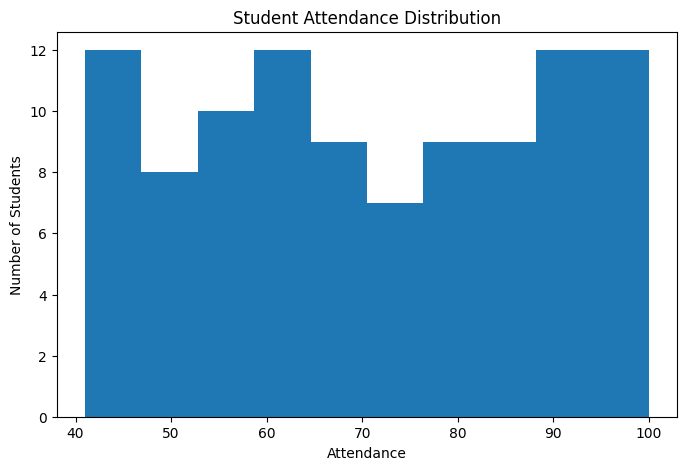

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df["Attendance"], bins=10)
plt.title("Student Attendance Distribution")
plt.xlabel("Attendance")
plt.ylabel("Number of Students")
plt.show()

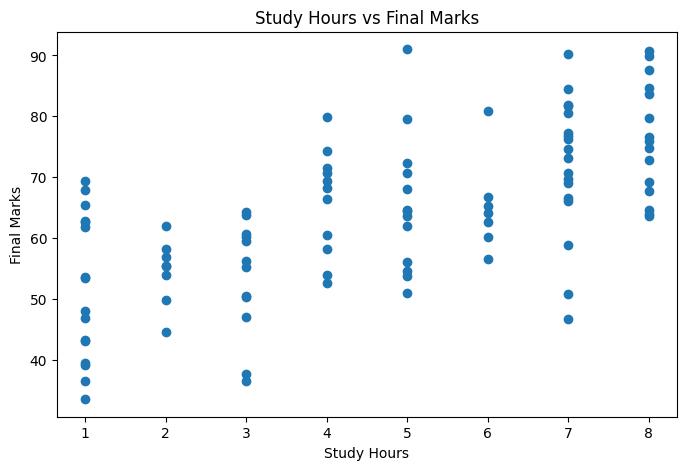

In [9]:
plt.figure(figsize=(8,5))
plt.scatter(df["Study_Hours"], df["Final_Marks"])
plt.title("Study Hours vs Final Marks")
plt.xlabel("Study Hours")
plt.ylabel("Final Marks")
plt.show()

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Machine Learning Libraries Imported Successfully!")

Machine Learning Libraries Imported Successfully!


In [12]:
# Input Features
X = df[
    ["Attendance", "Study_Hours",
     "Previous_Marks", "Assignment_Marks"]
]

# Target Output
y = df["Final_Marks"]

print("Input Data Shape:", X.shape)
print("Output Data Shape:", y.shape)

Input Data Shape: (100, 4)
Output Data Shape: (100,)


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 80
Testing Records: 20


In [15]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [17]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [19]:
import numpy as np

def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    print("\n", name)
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 2))

evaluate_model("Linear Regression", y_test, lr_predictions)
evaluate_model("Random Forest", y_test, rf_predictions)


 Linear Regression
MAE: 5.01
RMSE: 5.78
R2 Score: 0.83

 Random Forest
MAE: 6.6
RMSE: 7.97
R2 Score: 0.68


In [21]:
# New Student Details

new_student = pd.DataFrame({
    "Attendance": [85],
    "Study_Hours": [6],
    "Previous_Marks": [75],
    "Assignment_Marks": [80]
})

print("New Student Details:")
display(new_student)

New Student Details:


,Attendance,Study_Hours,Previous_Marks,Assignment_Marks
0,85,6,75,80


In [22]:
# Predict Student Final Marks

predicted_marks = lr_model.predict(new_student)

print("Student Performance Prediction")
print("--------------------------------")
print("Predicted Final Marks:",
      round(predicted_marks[0], 2))

Student Performance Prediction
--------------------------------
Predicted Final Marks: 77.55


In [25]:
marks = predicted_marks[0]

if marks >= 75:
    performance = "Excellent"
elif marks >= 60:
    performance = "Good"
elif marks >= 40:
    performance = "Average"
else:
    performance = "Needs Improvement"

print("Performance:", performance)

Performance: Excellent


In [26]:
print("===== STUDENT REPORT =====")
print("Attendance: 85%")
print("Study Hours: 6")
print("Previous Marks: 75")
print("Assignment Marks: 80")
print("Predicted Marks:", round(marks, 2))
print("Performance:", performance)
print("==========================")

===== STUDENT REPORT =====
Attendance: 85%
Study Hours: 6
Previous Marks: 75
Assignment Marks: 80
Predicted Marks: 77.55
Performance: Excellent


In [28]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from IPython.display import display, clear_output

# Dashboard Title
title = widgets.HTML(
    value="<h2>🎓 Student Performance Prediction Dashboard</h2>"
)

# Input sliders
attendance_slider = widgets.IntSlider(
    value=85, min=0, max=100, description="Attendance:"
)

study_slider = widgets.IntSlider(
    value=6, min=1, max=12, description="Study Hours:"
)

previous_slider = widgets.IntSlider(
    value=75, min=0, max=100, description="Previous Marks:"
)

assignment_slider = widgets.IntSlider(
    value=80, min=0, max=100, description="Assignment:"
)

predict_button = widgets.Button(
    description="Predict Performance",
    button_style="success"
)

output = widgets.Output()

# Prediction Function
def predict_student(button):
    with output:
        clear_output(wait=True)

        student = pd.DataFrame({
            "Attendance": [attendance_slider.value],
            "Study_Hours": [study_slider.value],
            "Previous_Marks": [previous_slider.value],
            "Assignment_Marks": [assignment_slider.value]
        })

        prediction = lr_model.predict(student)[0]
        prediction = float(np.clip(prediction, 0, 100))

        if prediction >= 75:
            category = "Excellent"
        elif prediction >= 60:
            category = "Good"
        elif prediction >= 40:
            category = "Average"
        else:
            category = "Needs Improvement"

        print("===== STUDENT PERFORMANCE REPORT =====")
        print("Predicted Marks:", round(prediction, 2))
        print("Performance:", category)

        # Dashboard Graph
        labels = [
            "Attendance",
            "Previous Marks",
            "Assignment Marks",
            "Predicted Marks"
        ]

        values = [
            attendance_slider.value,
            previous_slider.value,
            assignment_slider.value,
            prediction
        ]

        plt.figure(figsize=(9, 4))
        plt.bar(labels, values)
        plt.ylim(0, 100)
        plt.ylabel("Score")
        plt.title("Student Performance Dashboard")
        plt.xticks(rotation=15)
        plt.show()

predict_button.on_click(predict_student)

# Display Dashboard
display(title)
display(attendance_slider)
display(study_slider)
display(previous_slider)
display(assignment_slider)
display(predict_button)
display(output)

HTML(value='<h2>🎓 Student Performance Prediction Dashboard</h2>')

IntSlider(value=85, description='Attendance:')

IntSlider(value=6, description='Study Hours:', max=12, min=1)

IntSlider(value=75, description='Previous Marks:')

IntSlider(value=80, description='Assignment:')

Button(button_style='success', description='Predict Performance', style=ButtonStyle())

Output()

In [35]:
import joblib

# Save trained model
joblib.dump(lr_model, "student_performance_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [36]:
from google.colab import files

files.download("student_performance_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
# Export the DataFrame to a CSV file first
df.to_csv("student_performance.csv", index=False)

# Download the file to your local computer
files.download("student_performance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
df.to_csv("student_performance.csv", index=False)

print("CSV File Created Successfully!")

CSV File Created Successfully!


In [39]:
from google.colab import files

files.download("student_performance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>